# Classifying Research Abstracts into Science, Business and Social Science

**Goal:** build a baseline text-classification system that reads a paper's abstract and predicts its field (*Science*, *Business* or *Social Science*), then compare six classic ML models.

**Pipeline in this notebook**
1. Collect 1,500 abstracts from the OpenAlex API (500 per class)
2. Explore the data
3. Clean the text with NLP (lowercase, remove noise, stop-words, lemmatization)
4. Turn text into numbers with TF-IDF
5. Train six classifiers: Logistic Regression, Decision Tree, Naive Bayes, kNN, SVM, Random Forest
6. Compare them with accuracy, precision, recall, F1, cross-validation and plots
7. Interpret the results with confusion matrices and the most important words per class
8. Save the best model and a ~100-record demo dataset for the Streamlit app

## Step 0: Imports
Install any missing packages first with `pip install -r requirements.txt`.

In [97]:
import os
import requests
import pandas as pd
import numpy as np
import joblib
import re
import matplotlib.pyplot as plt
import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import MultinomialNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, classification_report)

RANDOM_STATE = 42     # makes results repeatable

## Step 1: Data collection from OpenAlex

[OpenAlex](https://openalex.org) is a free, open catalogue of scholarly papers. Every paper has a **primary topic**, and each topic belongs to a **field**. We use the field to create our label:

| Our label | OpenAlex fields used (field id) |
|---|---|
| Science | Agricultural and Biological Sciences (11), Biochemistry, Genetics and Molecular Biology (13), Chemistry (16), Computer Science (17), Earth and Planetary Sciences (19), Energy (21), Engineering (22), Environmental Science (23), Immunology and Microbiology (24), Materials Science (25), Mathematics (26), Medicine (27), Neuroscience (28), Pharmacology, Toxicology and Pharmaceutics (30), Physics and Astronomy (31), Health Professions (36) |
| Business | Business, Management and Accounting (14) |
| Social Science | Social Sciences (33), Psychology (32) | 

Two things to know:
* OpenAlex does not return abstracts as plain text. It returns an **inverted index** (`{"word": [positions]}`) so we have to rebuild the sentence.
* We ask for random samples (`sample` + `seed`) so the dataset is not biased toward one journal or year, and the `seed` makes it repeatable.
* We keep downloading until we have **500 abstracts per class**.

The data is downloaded once and saved to `dataset.csv`. If that file already exists, the download is skipped.

In [98]:
CLASSES = {
    "science":        [11, 13, 16, 17, 19, 21, 22, 23, 24, 25, 26, 27, 28, 30, 31, 36],  # Physics, Chemistry, Biochemistry, Computer Science, Earth Science, etc
    "business":       [14],              # Business, Management and Accounting
    "social science": [33, 32],              # Social Sciences, Psychology
}

RECORDS_PER_CLASS = 512
URL = "https://api.openalex.org/works"

# OpenAlex gives abstracts as an "inverted index"
#         e.g. {"deep": [0], "learning": [1], "works": [2]}
#         so we rebuild the normal sentence from word positions
def rebuild_abstract(inverted_index):
    words = {}
    for word, positions in inverted_index.items():
        for p in positions:
            words[p] = word
    return " ".join(words[i] for i in sorted(words))

# Download n random abstracts for one field
def fetch_abstracts(field_id, n):
    abstracts = []
    page = 1
    while len(abstracts) < n:
        params = {
            "filter": f"primary_topic.field.id:{field_id},has_abstract:true,type:article,language:en,publication_year:2000-2026",
            "sample": n,              # take a random sample of n papers
            "seed": RANDOM_STATE,     # fixed seed -> same results every run
            "per-page": 200,          # max allowed by OpenAlex
            "page": page,
            "select": "id,title,abstract_inverted_index,publication_year",
        }
        results = requests.get(URL, params=params, timeout=60).json()["results"]
        if not results:
            break
        for work in results:
            abstracts.append({"id": work["id"], "title": work["title"], "year": work["publication_year"],
                         "abstract": rebuild_abstract(work["abstract_inverted_index"])})
        page += 1
    return abstracts[:n]

file_path = "dataset.csv"

# Check if it exists, otherwise download and save it
if os.path.exists(file_path):
    print("Dataset already exists. Loading it...")
    df = pd.read_csv("dataset.csv")
else:
    print("Dataset not found. Downloading it...")
    #For each class, split the 500 records equally across its fields
    rows = []
    for label, field_ids in CLASSES.items():
        per_field = RECORDS_PER_CLASS // len(field_ids)
        for field_id in field_ids:
            print(f"Downloading {per_field} abstracts for '{label}' (field {field_id})...")
            for text in fetch_abstracts(field_id, per_field):
                text["label"] = label
                rows.append(text)

    df = pd.DataFrame(rows)
    df = df.sample(frac=1, random_state=RANDOM_STATE).reset_index(drop=True)  # shuffle
    df.to_csv("dataset.csv", index=False)
print(df["label"].value_counts())
print(df.shape)
df.head()

Dataset not found. Downloading it...
label
social science    512
science           512
business          512
Name: count, dtype: int64
(1536, 5)


,id,title,year,abstract,label
0,https://openalex.org/W7216557499,IMPLEMENTASI KEBIJAKAN WALI NAGARI DALAM PEMBA...,2022,Taxes are mandatory contributions to the state...,social science
1,https://openalex.org/W2313555653,Efficient Separation of Ar and Kr from Environ...,2016,"Radioactive noble-gas isotopes, 85Kr (half-lif...",science
2,https://openalex.org/W4402556039,Multi-Exciton and Phonon Dynamics Impact Intra...,2024,Intraband transitions in colloidal quantum dot...,science
3,https://openalex.org/W2343760868,Resíduos e justiça ambiental no Parque Guaraci...,2015,Submitted by Rafaella Monterei (rcarine@stj.ju...,social science
4,https://openalex.org/W627546647,Mind Shapes: Understanding the Differences in ...,2005,"In our everyday encounters, we are continuousl...",social science


## Step 2: Data Exploration and Cleaning

We examine the dataset and prepare it for classification by removing incomplete, duplicate, and unusable records, then rebalancing the classes.

1. **Remove missing abstract.** Drop records missing an abstract.
2. **Remove duplicates.** Remove duplicate records so repeated examples do not bias the analysis or model.
3. **Filter short abstracts.** Remove abstracts that are too short to provide meaningful information for classification.
4. **Rebalance the classes.** After cleaning, adjust the class distribution so that no class is disproportionately represented.

In [99]:
df["n_words_raw"] = df["abstract"].str.split().str.len()
df = (df[df["n_words_raw"] >= 50]
        .drop_duplicates(subset="abstract")
        .reset_index(drop=True))
df.to_csv("dataset.csv", index=False)
print("Records after cleaning:", len(df))
print(df["label"].value_counts())

# Run after cleaning the dataset
min_class_size = df["label"].value_counts().min()

df = (
    df.groupby("label", group_keys=False)
      .sample(n=min_class_size, random_state=42)
      .reset_index(drop=True)
)
print("Class counts after rebalancing:")
print(df["label"].value_counts())
print("Final dataset size:", df.shape)
df[["title", "label", "abstract"]].head()

Records after cleaning: 1415
label
business          488
social science    476
science           451
Name: count, dtype: int64
Class counts after rebalancing:
label
business          451
science           451
social science    451
Name: count, dtype: int64
Final dataset size: (1353, 6)


,title,label,abstract
0,Public Health Taxes: Should Sugar-Sweetened Be...,business,Due to increasing health concerns associated w...
1,A review of the research developments on inven...,business,Growth outlines the behavior of a class of inv...
2,Neuromarketing: Deep Motivations of the Consum...,business,In a society where information and knowledge h...
3,Analisis Perlakuan Akuntansi Syariah Pada Pemb...,business,The accounting treatment for murabahah financi...
4,MOLDOVAN AGRIFOOD TRADE POTENTIAL IN THE FRAME...,business,The agri-food trade of the Republic of Moldova...


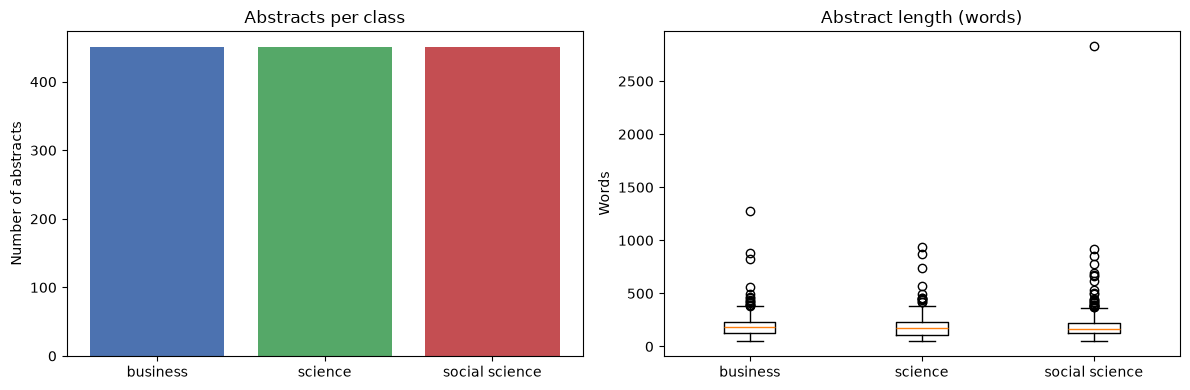

In [100]:
df["n_words"] = df["abstract"].str.split().str.len()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Left: how many abstracts per class
counts = df["label"].value_counts()
axes[0].bar(counts.index, counts.values, color=["#4C72B0", "#55A868", "#C44E52"])
axes[0].set_title("Abstracts per class")
axes[0].set_ylabel("Number of abstracts")

# Right: abstract length distribution
labels = df["label"].unique()
word_counts = [df.loc[df["label"] == label, "n_words"] for label in labels]

axes[1].boxplot(word_counts, tick_labels=labels)
axes[1].set_title("Abstract length (words)")
axes[1].set_ylabel("Words")

plt.tight_layout()
plt.show()

## 3. Text preprocessing (NLP)
Models need numbers, not raw prose, and raw prose is noisy. Our cleaning function:

1. **Lowercase** so "Model" and "model" are the same token.
2. **Remove non-letters** (digits, punctuation, symbols).
3. **Tokenize** by splitting on whitespace.
4. **Remove stop-words** (the, and, of ...) because they carry no topic information. We also remove generic academic words (study, paper, results ...) that appear in every field.
5. **Lemmatize** (studies → study, running → run) so word variants share one feature.
6. Drop tokens shorter than 3 characters.

In [101]:
nltk.download("stopwords", quiet=True)
nltk.download("wordnet", quiet=True)
nltk.download("omw-1.4", quiet=True)

ACADEMIC_STOP = {"study", "paper", "result", "results", "using", "use", "used", "also", "based",
                 "show", "shown", "however", "may", "can", "within", "among", "article", "research",
                 "analysis", "find", "found", "finding", "findings", "propose", "present", "approach"}
STOP = set(stopwords.words("english")) | ACADEMIC_STOP
lemmatizer = WordNetLemmatizer()

def clean_text(text):
    text = str(text).lower()
    text = re.sub(r"[^a-z\s]", " ", text)
    tokens = [lemmatizer.lemmatize(t) for t in text.split()]
    tokens = [t for t in tokens if t not in STOP and len(t) > 2]
    return " ".join(tokens)

example = df["abstract"].iloc[0]
print("BEFORE:", example[:300], "...\n")
print("AFTER :", clean_text(example)[:300], "...")

BEFORE: Due to increasing health concerns associated with sugar consumption, the World Health Organization (WHO) has recommended the implementation of taxes targeting sugar-sweetened beverages (SSBs). This article endeavours to reconnect the actual research with the potential legal framework for SSB taxatio ...

AFTER : due increasing health concern associated sugar consumption world health organization recommended implementation tax targeting sugar sweetened beverage ssbs endeavour reconnect actual potential legal framework ssb taxation comparative objective provide policymakers insight whether introduce taxation  ...


In [102]:
df["clean"] = df["abstract"].apply(clean_text)
df["n_words_clean"] = df["clean"].str.split().str.len()
df = df[df["n_words_clean"] > 10].reset_index(drop=True)   # drop anything that became (almost) empty
print(df[["label", "n_words_raw", "n_words_clean"]].groupby("label").mean().round(1))

                n_words_raw  n_words_clean
label                                     
business              191.3          112.0
science               184.5          108.0
social science        194.5          112.3


## 4. Train / test split
**Train/test split:** we keep 20% of the data hidden from the models until the very end, so the final scores show how well they handle *unseen* abstracts. `stratify` keeps the class proportions equal in both parts, and the random seed makes the split repeatable.

In [103]:
X_train_text, X_test_text, y_train, y_test = train_test_split(
    df["clean"], df["label"],
    test_size=0.2, stratify=df["label"], random_state=RANDOM_STATE
)
print("Training records:", len(X_train_text), "| Test records:", len(X_test_text))

Training records: 1074 | Test records: 269


## 5. Feature extraction with TF-IDF
**TF-IDF** turns each abstract into a numeric vector. A word gets a high weight if it is frequent in *this* abstract but rare across the whole collection (so "polymer" is informative, "model" is not).

Settings: unigrams + bigrams (`ngram_range=(1,2)`), ignore terms in fewer than 3 documents (`min_df=2`), keep the top 6000 features, and use sublinear term-frequency scaling.

To avoid **data leakage**, the vectorizer must learn its vocabulary only from training data. We guarantee this by putting TF-IDF and the classifier together in a scikit-learn `Pipeline`: when we call `.fit()` on training text, only that text is used.

In [104]:
tfidf = TfidfVectorizer(max_features=6000, ngram_range=(1, 2), min_df=2)
X_train = tfidf.fit_transform(X_train_text)   # learn vocabulary on train, then transform
X_test = tfidf.transform(X_test_text)         # only transform test (no learning)
print("Feature matrix shape (train):", X_train.shape)

Feature matrix shape (train): (1074, 6000)


## Step 6: Train the six classifiers
| Model | One-line idea |
|---|---|
| Logistic Regression | Learns a weight per word and turns the weighted sum into class probabilities |
| Decision Tree | Asks a series of yes/no questions about words |
| Naive Bayes | Uses word-frequency probabilities per class (assumes words are independent) |
| kNN | Looks at the *k* most similar training abstracts and takes a vote |
| SVM | Finds the boundary that separates classes with the widest margin |
| Random Forest | Many decision trees voting together |

We use mostly default settings, since this is a **baseline**.

In [105]:
def build_models():
    return {
        "Logistic Regression": LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
        "Decision Tree":       DecisionTreeClassifier(random_state=RANDOM_STATE),
        "Naive Bayes":         MultinomialNB(),
        "kNN":                 KNeighborsClassifier(n_neighbors=5, metric="cosine"),
        "SVM":                 SVC(kernel="linear"),
        "Random Forest":       RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE),
    }

models = build_models()
predictions = {}

for name, model in models.items():
    model.fit(X_train, y_train)                    # learn from the training data
    predictions[name] = model.predict(X_test)      # predict the unseen test data
    print(f"{name:20s} trained | test accuracy = {accuracy_score(y_test, predictions[name]):.3f}")

Logistic Regression  trained | test accuracy = 0.859
Decision Tree        trained | test accuracy = 0.669
Naive Bayes          trained | test accuracy = 0.848
kNN                  trained | test accuracy = 0.781
SVM                  trained | test accuracy = 0.840
Random Forest        trained | test accuracy = 0.825


## Step 7: Evaluate the models
Metrics (macro = average across the three classes, each class counts equally):
* **Accuracy**: share of all predictions that are correct
* **Precision**: of the abstracts predicted as class X, how many really are X?
* **Recall**: of the abstracts that really are X, how many did we find?
* **F1-score**: balance of precision and recall

In [106]:
results = []
for name, y_pred in predictions.items():
    results.append({
        "Model": name,
        "Accuracy":  accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, average="macro"),
        "Recall":    recall_score(y_test, y_pred, average="macro"),
        "F1-score":  f1_score(y_test, y_pred, average="macro"),
    })

results_df = pd.DataFrame(results).set_index("Model").sort_values("F1-score", ascending=False)
results_df.round(3)

,Accuracy,Precision,Recall,F1-score
Model,,,,
Logistic Regression,0.859,0.864,0.859,0.860
Naive Bayes,0.848,0.860,0.848,0.849
SVM,0.840,0.843,0.840,0.841
Random Forest,0.825,0.829,0.825,0.825
kNN,0.781,0.783,0.780,0.780
Decision Tree,0.669,0.672,0.669,0.670


## Step 8: Visualizations
### 8.1 Model comparison

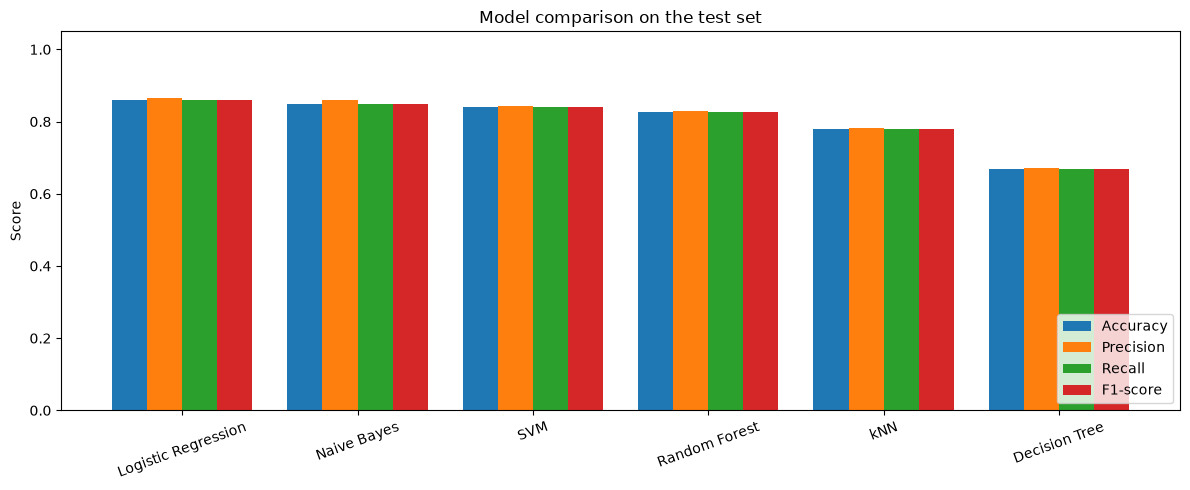

In [107]:
metrics = ["Accuracy", "Precision", "Recall", "F1-score"]
x = np.arange(len(results_df))
width = 0.2

fig, ax = plt.subplots(figsize=(12, 5))
for i, metric in enumerate(metrics):
    ax.bar(x + i * width, results_df[metric], width, label=metric)

ax.set_xticks(x + 1.5 * width)
ax.set_xticklabels(results_df.index, rotation=20)
ax.set_ylim(0, 1.05)
ax.set_ylabel("Score")
ax.set_title("Model comparison on the test set")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

### 8.2 Confusion matrices
A confusion matrix shows **what each model predicted (columns) versus the truth (rows)**. Numbers on the diagonal are correct predictions; numbers off the diagonal are mistakes, and they show *which* classes get confused with each other.

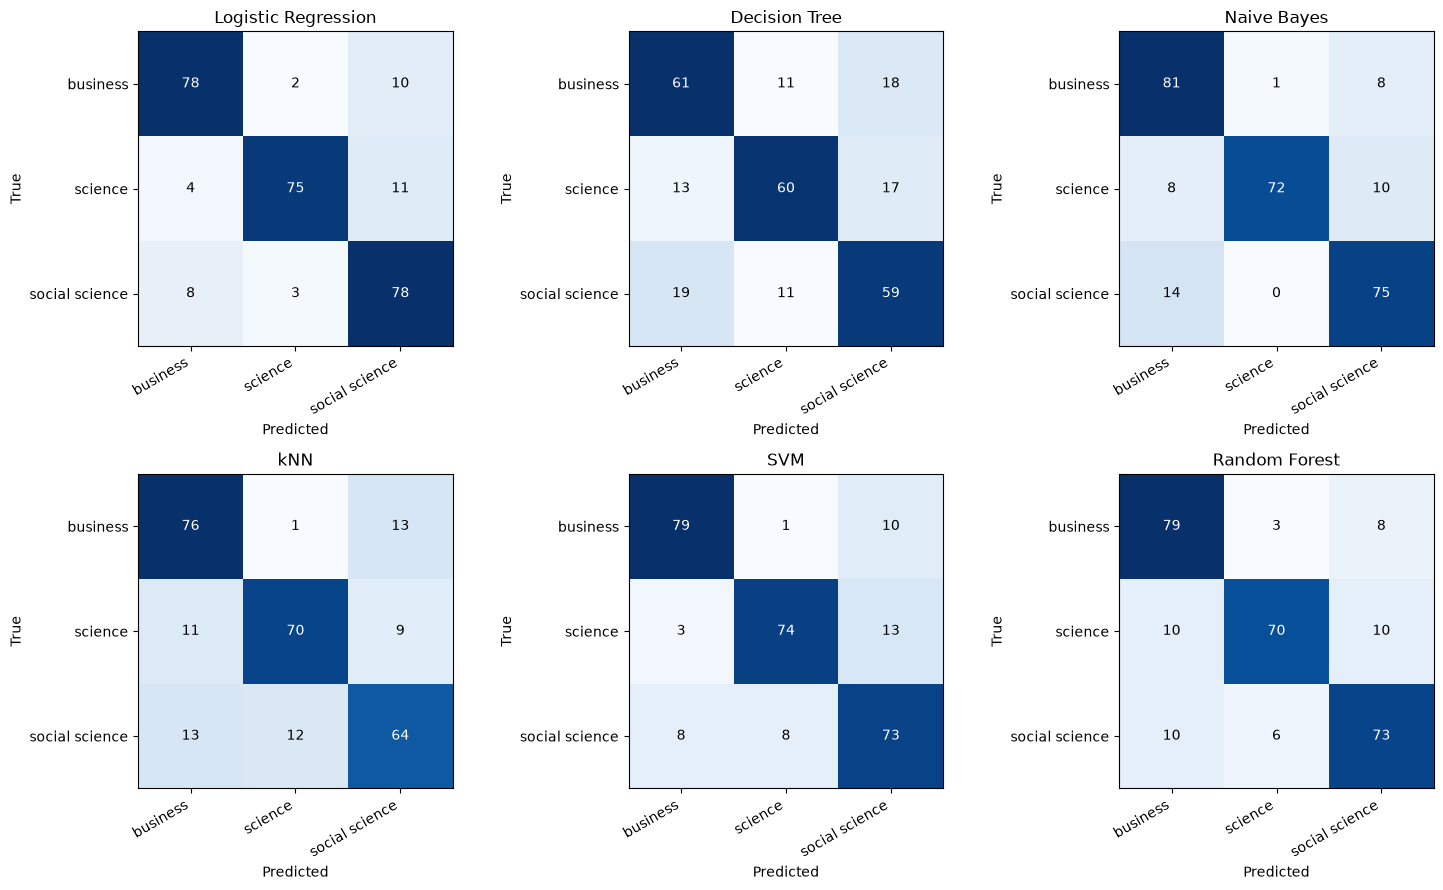

In [108]:
class_names = sorted(df["label"].unique())

def plot_confusion(ax, y_true, y_pred, title):
    cm = confusion_matrix(y_true, y_pred, labels=class_names)
    ax.imshow(cm, cmap="Blues")
    ax.set_title(title)
    ax.set_xticks(range(len(class_names)))
    ax.set_yticks(range(len(class_names)))
    ax.set_xticklabels(class_names, rotation=30, ha="right")
    ax.set_yticklabels(class_names)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("True")
    for i in range(len(class_names)):
        for j in range(len(class_names)):
            colour = "white" if cm[i, j] > cm.max() / 2 else "black"
            ax.text(j, i, cm[i, j], ha="center", va="center", color=colour)

fig, axes = plt.subplots(2, 3, figsize=(15, 9))
for ax, name in zip(axes.ravel(), predictions):
    plot_confusion(ax, y_test, predictions[name], name)
plt.tight_layout()
plt.show()

### 8.3 Per-class F1-score
Do the models find some classes harder than others?

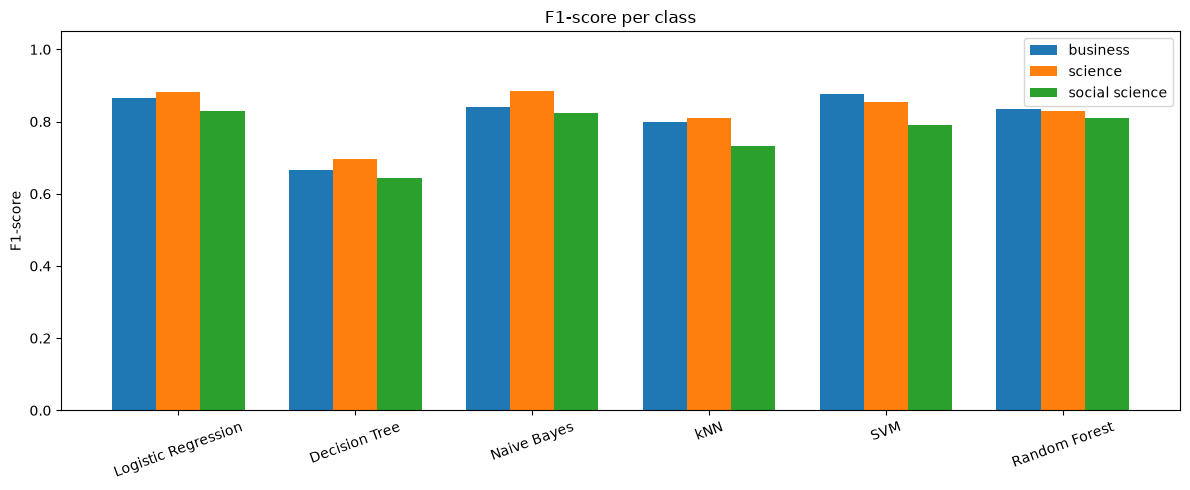

In [109]:
per_class_f1 = {name: f1_score(y_test, y_pred, average=None, labels=class_names)
                for name, y_pred in predictions.items()}
per_class_df = pd.DataFrame(per_class_f1, index=class_names).T

x = np.arange(len(per_class_df))
width = 0.25
fig, ax = plt.subplots(figsize=(12, 5))
for i, cls in enumerate(class_names):
    ax.bar(x + i * width, per_class_df[cls], width, label=cls)
ax.set_xticks(x + width)
ax.set_xticklabels(per_class_df.index, rotation=20)
ax.set_ylim(0, 1.05)
ax.set_ylabel("F1-score")
ax.set_title("F1-score per class")
ax.legend()
plt.tight_layout()
plt.show()

## Step 9: Best model, detailed report and error analysis

In [112]:
best_name = results_df["F1-score"].idxmax()
best_model = models[best_name]
print("Best model:", best_name)
print()
print(classification_report(y_test, predictions[best_name]))

Best model: Logistic Regression

                precision    recall  f1-score   support

      business       0.87      0.87      0.87        90
       science       0.94      0.83      0.88        90
social science       0.79      0.88      0.83        89

      accuracy                           0.86       269
     macro avg       0.86      0.86      0.86       269
  weighted avg       0.86      0.86      0.86       269



In [113]:
# Look at some abstracts the best model got wrong
errors = pd.DataFrame({
    "title": df.loc[X_test_text.index, "title"],
    "true": y_test,
    "predicted": predictions[best_name],
})
errors = errors[errors["true"] != errors["predicted"]]
print(f"{len(errors)} mistakes out of {len(y_test)} test abstracts\n")
errors.head(10)

38 mistakes out of 269 test abstracts



,title,true,predicted
592,Midfrontal mechanisms of performance monitorin...,science,business
663,Examining prisoner experience of an equine ass...,science,social science
52,The concept of a draft of the federal law “On ...,business,social science
867,Planning in the Fluent Calculus Using Binary D...,science,social science
13,THE VIOLATION OF PUBLIC POLICY AS ONE OF THE C...,business,social science
410,DOAÇÃO DE SANGUE NO ESTADO DE SÃO PAULO,business,science
431,Literature Paving the Way for Law: ADR as an I...,business,social science
797,Creating a Shared Understanding of Institution...,science,social science
916,Customer engagement in Acehnese traditional re...,social science,business
738,An Investigation into Equine Nutrition Knowled...,science,social science


**Why do mistakes happen?** Business and Social Science overlap a lot (e.g. economics, management and sociology papers share vocabulary), and a paper's OpenAlex field is only a single automatic label, so some abstracts could honestly belong to two classes. This is a natural limit of a bag-of-words baseline.

## Step 10: Save outputs for the Streamlit demo
We save:
* `model/artifacts.joblib`: the TF-IDF vectorizer, all six trained models, and the name of the best model
* `demo_test_data.csv`: ~100 records **taken from the unseen test set**, for trying the demo
* `openalex_abstracts.csv`: the full labelled dataset (saved earlier)

In [115]:
os.makedirs("model", exist_ok=True)
joblib.dump({
    "vectorizer": tfidf,
    "models": models,
    "best_model": best_name,
    "metrics": results_df.reset_index(),
    "classes": class_names,
}, "model/artifacts.joblib")

# ~100 balanced demo records from the test set (33-34 per class)
test_df = df.loc[X_test_text.index, ["title", "abstract", "label"]]

demo_df = (test_df.groupby("label", group_keys=False)
                  .apply(lambda g: g.sample(n=min(34, len(g)), random_state=RANDOM_STATE))
                  .sample(frac=1, random_state=RANDOM_STATE)
                  .head(100))
demo_df.to_csv("demo_test_data.csv", index=False)
print("Saved model/artifacts.joblib and demo_test_data.csv with", len(demo_df), "records")

Saved model/artifacts.joblib and demo_test_data.csv with 100 records


## Step 11: Conclusions
* **Best model:** Logistic Regression, with test accuracy **0.859** and macro F1 **0.860**. Naive Bayes was the next strongest model (macro F1 **0.849**).
* **Weakest model:** Decision Tree, with accuracy **0.669** and macro F1 **0.670**; a single tree likely struggles to generalize from sparse, high-dimensional TF-IDF features.
* **Per-class performance:** Logistic Regression achieved F1 scores of **0.867** for business, **0.882** for science, and **0.830** for social science. Social science was its most challenging class.
* **Interpretation:** The results suggest that TF-IDF features capture useful distinctions between fields, though performance varies by class. Refer to the feature-importance output to discuss specific top words.
* **Limitations:** Labels come from OpenAlex's automatic topic classification; only abstracts (not full text) are used; no hyperparameter tuning was performed.
* **Future work:** Try hyperparameter search, word embeddings or transformer models, additional classes, and a larger dataset.